# Mid-project review — try to challenge our causal estimates

**Purpose:** check whether the analysis behaves sensibly when we deliberately change the data. This follows the supplied mid-project review requirement using DoWhy and EconML.

**Important correction to the project wording:** no refutation test can mathematically prove that all hidden confounders have been removed. We can test specific weaknesses and report sensitivity under stated assumptions. Hillstrom's randomized assignment is the main basis for causal interpretation.

The previous notebook used older files and only 10 repetitions. This notebook uses notebook 02's engineered features, checks the actual notebook 05 model exports, uses 30 repetitions per refuter, and records the exact scope and limitations. Run notebooks 02 and 05 first using the same Python environment. DoWhy is an additional dependency; if needed use `%pip install dowhy` in the selected notebook kernel and restart it.

**Two separate checks:**
1. Verify the exact saved three-arm model and its held-out exports from notebook 05.
2. Refit smaller, training-only pairwise causal forests inside DoWhy to run repeated perturbations. These test the modelling approach for the primary outcome `visit`, not the exact saved model or every customer score. Purchase/spend refutation and full-size repeated retraining remain outside this classroom audit.

The audit writes `results/mid_project_audit/`. It does not alter the trained models or their independent evaluation.

In [1]:
from pathlib import Path
import json
import hashlib
import logging
import time
from importlib.metadata import version
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from dowhy import CausalModel

SEED = 42
SIMULATIONS = 30
AUDIT_ROWS = 3000
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/raw/hillstrom.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open the repository with data/raw/hillstrom.csv.")
OUTPUT = ROOT / "results/mid_project_audit"
OUTPUT.mkdir(parents=True, exist_ok=True)
logging.getLogger("dowhy").setLevel(logging.ERROR)
paths = ["data/processed/causal_train.csv", "data/processed/causal_test.csv",
         "results/causal_preprocessing_summary.json", "results/double_ml/test_scores.csv",
         "results/double_ml/model_info.json", "models/double_ml/double_ml_bundle.joblib",
         "results/double_ml/ranking_evaluation.csv"]
missing = [p for p in paths if not (ROOT / p).exists()]
if missing:
    raise FileNotFoundError("Run notebooks 02 and 05 first. Missing: " + ", ".join(missing))
train = pd.read_csv(ROOT / paths[0])
test = pd.read_csv(ROOT / paths[1]).sort_values("customer_id").reset_index(drop=True)
prep = json.loads((ROOT / paths[2]).read_text())
features = prep["feature_columns_after_encoding"]
assert not set(features).intersection({"visit", "conversion", "spend", "treatment", "customer_id"})
assert set(train.customer_id).isdisjoint(test.customer_id)
assert train.customer_id.is_unique and test.customer_id.is_unique
assert np.isfinite(train[features + ["visit"]].to_numpy()).all()
print("DoWhy", version("dowhy"), "EconML", version("econml"))
print("Audit uses training rows only; test outcomes do not select refutation settings.")

/Users/sharath/economl_project-1/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DoWhy 0.14 EconML 0.17.0
Audit uses training rows only; test outcomes do not select refutation settings.


## 1. Check the exact final model first

Imagine checking a saved calculator: does it still give the same answer after reopening it? Here we reload the actual trained models, recompute all held-out effects, and compare them with the exported scores. We also check the source and prepared-data fingerprints. This catches file/version mixing; it is **not a causal refutation**.

Only load model files you created locally or trust. Joblib files can execute code when loaded.

In [2]:
info = json.loads((ROOT / paths[4]).read_text())
assert info["raw_sha256"] == hashlib.sha256((ROOT / "data/raw/hillstrom.csv").read_bytes()).hexdigest()
for path, expected in info["input_sha256"].items():
    assert hashlib.sha256((ROOT / path).read_bytes()).hexdigest() == expected, f"Changed input: {path}. Rerun 05."
bundle = joblib.load(ROOT / paths[5])
assert bundle["encoded_features"] == features
saved = pd.read_csv(ROOT / paths[3]).set_index("customer_id").loc[test.customer_id]
assert np.array_equal(saved.treatment.to_numpy(), test.treatment.to_numpy())
assert np.array_equal(saved[["visit", "conversion", "spend"]].to_numpy(), test[["visit", "conversion", "spend"]].to_numpy())
model_checks = []
for outcome, model in bundle["models"].items():
    for arm, name in [(1, "mens"), (2, "womens")]:
        prediction = model.effect(test[features].to_numpy(), T0=0, T1=arm).ravel()
        error = float(np.max(np.abs(prediction - saved[f"{outcome}_{name}"].to_numpy())))
        assert np.isfinite(prediction).all() and error < 1e-9
        model_checks.append({"outcome": outcome, "arm": name, "maximum_export_error": error})
display(pd.DataFrame(model_checks))
ranking = pd.read_csv(ROOT / paths[6])
display(ranking)
print("Exact-model exports verified. Ranking uncertainty remains as reported by notebook 05.")

,outcome,arm,maximum_export_error
0,visit,mens,2.220446e-16
1,visit,womens,2.498002e-16
2,conversion,mens,1.058181e-16
3,conversion,womens,1.075529e-16
4,spend,mens,3.996803e-15
5,spend,womens,4.440892e-15


,outcome,email,test_pair_rows,normalized_qini,lower95,upper95,finding
0,visit,mens,12784,0.003355,-0.000773,0.007032,Ranking advantage uncertain
1,visit,womens,12808,0.010279,0.006793,0.014289,Positive ranking evidence (exploratory)
2,conversion,mens,12784,0.000335,-0.000702,0.001359,Ranking advantage uncertain
3,conversion,womens,12808,0.000965,0.000033,0.001863,Positive ranking evidence (exploratory)
4,spend,mens,12784,0.085616,-0.079665,0.242443,Ranking advantage uncertain
5,spend,womens,12808,0.114626,-0.047692,0.272670,Ranking advantage uncertain


Exact-model exports verified. Ranking uncertainty remains as reported by notebook 05.


## 2. Define a smaller, clearly labelled audit model

For each email versus no email, we take a reproducible treatment-stratified sample of 3,000 **training** rows. The treatment remains binary in this audit. The randomized DAG has `email → visit` and baseline features `→ visit`; it has no baseline arrow into email assignment.

The smaller causal forest has 40 trees, two cross-fitting folds, and Random Forest nuisance models with 20 trees. We use the same 16 engineered baseline inputs as notebook 05. Smaller repeated fits make the notebook practical on a laptop. Do not call their estimates the final three-arm model's estimates.

This DAG needs no backdoor adjustment under randomization. Baseline features are supplied as effect modifiers to learn heterogeneous effects. `target_units='ate'` averages over this audit sample, not the entire population.

In [3]:
def make_audit_model(pair):
    graph = "digraph { treatment -> visit; " + "; ".join(f'"{x}" -> visit' for x in features) + "; }"
    causal = CausalModel(data=pair, treatment="treatment", outcome="visit", graph=graph)
    estimand = causal.identify_effect()
    assert estimand.get_backdoor_variables() == []
    estimate = causal.estimate_effect(estimand,
        method_name="backdoor.econml.dml.CausalForestDML", effect_modifiers=features,
        control_value=0, treatment_value=1, target_units="ate",
        method_params={"init_params": {
            "model_y": RandomForestRegressor(n_estimators=20, min_samples_leaf=40,
                                               max_depth=8, random_state=SEED, n_jobs=2),
            "model_t": RandomForestClassifier(n_estimators=20, min_samples_leaf=40,
                                                max_depth=8, random_state=SEED, n_jobs=2),
            "discrete_treatment": True, "categories": [0, 1], "cv": 2,
            "n_estimators": 40, "min_samples_leaf": 60, "max_depth": 8,
            "honest": True, "inference": True, "n_jobs": 2, "random_state": SEED},
            "fit_params": {}})
    return causal, estimand, estimate

pairs, audit_models = {}, {}
for arm, name in [(1, "Mens E-Mail"), (2, "Womens E-Mail")]:
    full_pair = train.loc[train.treatment.isin([0, arm])].copy()
    count = min(AUDIT_ROWS, len(full_pair))
    if count < len(full_pair):
        pair, _ = train_test_split(full_pair, train_size=count, stratify=full_pair.treatment, random_state=SEED)
    else:
        pair = full_pair
    pair = pair[["customer_id", *features, "treatment", "visit"]].copy()
    pair["treatment"] = (pair.treatment == arm).astype(int)
    assert set(pair.customer_id).issubset(train.customer_id)
    assert set(pair.treatment) == {0, 1}
    pairs[name] = pair
    audit_models[name] = make_audit_model(pair)
    print(name, "audit rows:", len(pair), "estimated visit effect:", float(audit_models[name][2].value), flush=True)

Mens E-Mail audit rows: 3000 estimated visit effect: 0.0716447840199793


Womens E-Mail audit rows: 3000 estimated visit effect: 0.0710758507036211


## 3. Try three DoWhy refutations

| Test | Everyday example | Expected behaviour |
|---|---|---|
| Random common cause | Add a meaningless random column, like a coin toss | Effect should not change much |
| Placebo treatment | Shuffle who supposedly received the email | Estimated effect should move near zero |
| Data subset | Repeat using a random 80% of the audit rows | Effect should be reasonably stable |

Each refuter runs 30 perturbations and refits the smaller model. A seeded `RandomState` is advanced across repetitions, so we do not accidentally use the same shuffled sample each time.

The returned `new_effect` is the mean of the perturbed estimates. DoWhy reports diagnostic p-values: for placebo the reference is zero; for random-column and subset tests it is the original estimate. A large p-value is **failure to detect a discrepancy**, not proof of correctness. With only 30 repetitions, the library's significance approximation and limited test power require caution. We display numbers and interpretations, not a blanket “causality passed” badge.

In [4]:
audit = []
for name, (causal, estimand, estimate) in audit_models.items():
    checks = []
    for method in ["random_common_cause", "placebo_treatment_refuter", "data_subset_refuter"]:
        started = time.time()
        settings = {"method_name": method, "num_simulations": SIMULATIONS,
                    "random_state": np.random.RandomState(SEED), "n_jobs": 1}
        if method == "placebo_treatment_refuter": settings["placebo_type"] = "permute"
        if method == "data_subset_refuter": settings["subset_fraction"] = 0.8
        result = causal.refute_estimate(estimand, estimate, **settings)
        original, changed = float(result.estimated_effect), float(result.new_effect)
        assert np.isfinite([original, changed]).all()
        details = result.refutation_result or {}
        pvalue = details.get("p_value")
        pvalue = None if pvalue is None else float(np.asarray(pvalue).ravel()[0])
        if pvalue is not None and not np.isfinite(pvalue): pvalue = None
        reference = 0.0 if method == "placebo_treatment_refuter" else original
        checks.append({"test": method, "original": original, "after_change": changed,
                       "expected_reference": reference, "difference_from_reference": changed-reference,
                       "p_value": pvalue, "details": str(result), "simulations": SIMULATIONS})
        print(name, method, "changed effect:", round(changed, 5), "p:", pvalue,
              "seconds:", round(time.time()-started, 1), flush=True)
    audit.append({"arm": name, "rows": len(pairs[name]), "dml_effect": float(estimate.value),
                  "checks": checks, "scope": "Training-only pairwise visit audit: 3,000 rows, 40 trees, 30 repetitions per refuter. Not the final three-arm forest.",
                  "conclusion": "These checks can expose weaknesses; they cannot prove the absence of hidden confounding."})
refutation_table = pd.DataFrame([{"arm": a["arm"], **c} for a in audit for c in a["checks"]])
display(refutation_table.drop(columns="details"))

Mens E-Mail random_common_cause changed effect: 0.07137 p: 0.43087957343933925 seconds: 13.7


Mens E-Mail placebo_treatment_refuter changed effect: 0.00252 p: 0.41785928974041 seconds: 14.4


Mens E-Mail data_subset_refuter changed effect: 0.07513 p: 0.33388828070821197 seconds: 15.7


Womens E-Mail random_common_cause changed effect: 0.06995 p: 0.22420822337403545 seconds: 13.8


Womens E-Mail placebo_treatment_refuter changed effect: 0.00221 p: 0.4349543002400893 seconds: 13.6


Womens E-Mail data_subset_refuter changed effect: 0.0564 p: 0.040073782435687044 seconds: 12.3


,arm,test,original,after_change,expected_reference,difference_from_reference,p_value,simulations
0,Mens E-Mail,random_common_cause,0.071645,0.071366,0.071645,-0.000279,0.430880,30
1,Mens E-Mail,placebo_treatment_refuter,0.071645,0.002517,0.000000,0.002517,0.417859,30
2,Mens E-Mail,data_subset_refuter,0.071645,0.075125,0.071645,0.003481,0.333888,30
3,Womens E-Mail,random_common_cause,0.071076,0.069951,0.071076,-0.001125,0.224208,30
4,Womens E-Mail,placebo_treatment_refuter,0.071076,0.002208,0.000000,0.002208,0.434954,30
5,Womens E-Mail,data_subset_refuter,0.071076,0.056397,0.071076,-0.014679,0.040074,30


## 4. Hypothetical hidden-confounding stress scenarios

“What if our randomization/recording assumption were wrong?” We use DoWhy's `add_unobserved_common_cause` with binary label perturbations of 1%, 5%, and 10%. These are **chosen stress settings**, not estimated amounts of hidden confounding or realistic measured customer traits.

For this separate illustration we use a simple linear average-effect estimator on the same audit rows. In an unadjusted randomized binary comparison, its coefficient equals the difference in visit rates. We verify that identity independently. It is not a hidden-confounding sensitivity interval for the causal forest. A seed is reset for reproducibility of each scenario; these are single illustrative perturbations, not repeated uncertainty estimates.

The mathematical idea of omitted-variable bias is `observed difference = causal effect + hidden baseline difference`. If an unmeasured trait both changes assignment and changes outcomes, the group difference can be biased. Refutation cannot establish that this hidden term equals zero.

,assumed_flip_probability,original,perturbed,arm
0,0.00,0.073333,0.073333,Mens E-Mail
1,0.01,0.073333,0.076679,Mens E-Mail
2,0.05,0.073333,0.075959,Mens E-Mail
3,0.10,0.073333,0.083527,Mens E-Mail


,assumed_flip_probability,original,perturbed,arm
0,0.00,0.05684,0.056840,Womens E-Mail
1,0.01,0.05684,0.055333,Womens E-Mail
2,0.05,0.05684,0.048672,Womens E-Mail
3,0.10,0.05684,0.047129,Womens E-Mail


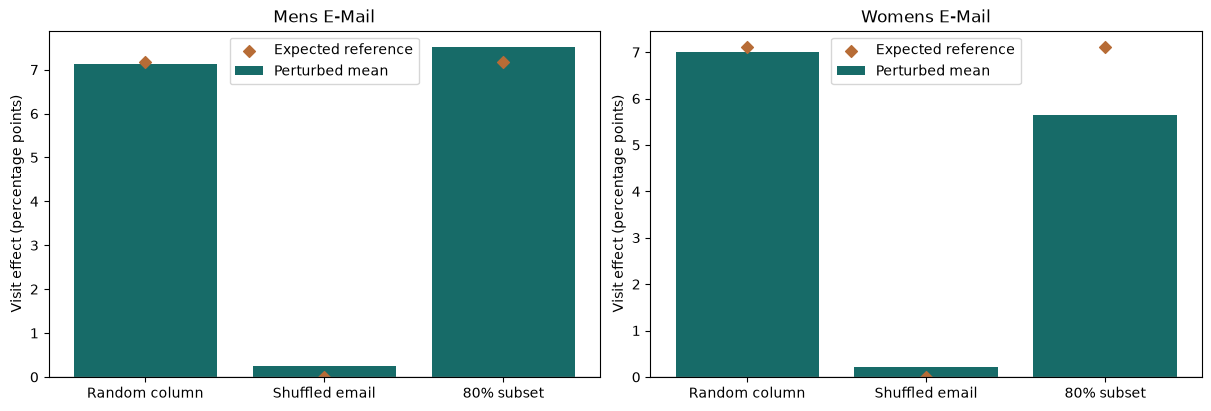

In [5]:
for record in audit:
    name = record["arm"]
    causal, estimand, _ = audit_models[name]
    average = causal.estimate_effect(estimand, method_name="backdoor.linear_regression",
                                    effect_modifiers=[], control_value=0, treatment_value=1)
    pair = pairs[name]
    direct = pair.loc[pair.treatment == 1, "visit"].mean() - pair.loc[pair.treatment == 0, "visit"].mean()
    assert np.isclose(float(average.value), direct, atol=1e-9)
    sensitivity = [{"assumed_flip_probability": 0.0, "original": float(average.value), "perturbed": float(average.value)}]
    for strength in [0.01, 0.05, 0.10]:
        np.random.seed(SEED)
        stress = causal.refute_estimate(estimand, average, method_name="add_unobserved_common_cause",
            confounders_effect_on_treatment="binary_flip", confounders_effect_on_outcome="binary_flip",
            effect_strength_on_treatment=strength, effect_strength_on_outcome=strength)
        value = float(stress.new_effect)
        assert np.isfinite(value)
        sensitivity.append({"assumed_flip_probability": strength, "original": float(average.value), "perturbed": value})
    record["sensitivity"] = sensitivity
    record["sensitivity_scope"] = "Separate linear average-effect model; single hypothetical shared label-perturbation scenarios. Not a forest confidence interval or evidence that these hidden causes exist."
    display(pd.DataFrame(sensitivity).assign(arm=name))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, record in zip(axes, audit):
    c = record["checks"]
    x = np.arange(len(c))
    ax.bar(x, [100*r["after_change"] for r in c], color="#176b68", label="Perturbed mean")
    ax.scatter(x, [100*r["expected_reference"] for r in c], color="#b76c36", marker="D", label="Expected reference")
    ax.set_xticks(x, ["Random column", "Shuffled email", "80% subset"])
    ax.axhline(0, color="grey", linewidth=1)
    ax.set(title=record["arm"], ylabel="Visit effect (percentage points)")
    ax.legend()
fig.savefig(OUTPUT / "refutation_summary.png", dpi=140)
plt.show()

## 5. Save the evidence for the dashboard

The dashboard will display these refutation values and the separate stress scenarios. It will also load the 64,000 model scores from notebook 05 and let users filter thousands of rows. Browser filtering, chart consistency, and CSV validation are tested separately; statistical checks do not verify a user interface.

To explain a test: “Our original estimate was A percentage points. After shuffling email labels, it became B. We expected B near zero because we intentionally broke the treatment relationship. That is reassuring only for this particular test.” Use the actual table above for A and B.

If a check changes substantially, report it and investigate sample size, model sensitivity and assumptions. Do not keep changing seeds until a test appears to pass.

In [6]:
report = {"audit": audit, "exact_model_checks": model_checks,
          "simulations": SIMULATIONS, "audit_rows_per_pair": AUDIT_ROWS,
          "outcome": "visit", "seed": SEED,
          "versions": {p: version(p) for p in ["dowhy", "econml", "numpy", "pandas", "scikit-learn"]},
          "source_sha256": info["raw_sha256"],
          "limits": ["Pairwise refits audit the model family, not the exact three-arm estimator.",
                     "Only the primary visit outcome is refuted; purchase/spend are not audited here.",
                     "Thirty perturbations are an exploratory check, not a high-power confirmatory test.",
                     "No test proves absence of hidden confounding.",
                     "Sensitivity scenarios use a separate linear model and assumed label changes."]}
(OUTPUT / "audit.json").write_text(json.dumps(report, indent=2, allow_nan=False))
refutation_table.to_csv(OUTPUT / "refutation_results.csv", index=False)
pd.DataFrame(model_checks).to_csv(OUTPUT / "exact_model_checks.csv", index=False)
for name, pair in pairs.items():
    pair[["customer_id", "treatment"]].to_csv(OUTPUT / ("mens_audit_rows.csv" if name.startswith("Mens") else "womens_audit_rows.csv"), index=False)
print("Audit saved. Exact-model export checks and both independent average-effect checks passed.")
print("Report refutation values and limitations together; never state that hidden confounding was mathematically eliminated.")

Audit saved. Exact-model export checks and both independent average-effect checks passed.
Report refutation values and limitations together; never state that hidden confounding was mathematically eliminated.


## Interview answer

“I used DoWhy to challenge the analysis. Adding random information and dropping some rows tested stability; shuffling treatment tested whether the model invented an effect after the real assignment relationship was broken. I separately explored hypothetical hidden-confounding violations. I verified the final saved model, but repeated refutations used smaller training-only pairwise models for laptop runtime. These checks support an audit trail; they cannot prove that every causal assumption is true.”

[DoWhy refutation documentation](https://www.pywhy.org/dowhy/v0.9.1/user_guide/effect_inference/refute.html) explains the tests. The notebook prints the installed version because implementation details and p-value calculations may differ across releases. The project images and guide request refutations and dashboard load validation; neither task justifies guaranteeing causality.

## Findings from the verified run

| Email | Original audit effect | Random-column mean | Shuffled-email mean | 80% subset mean |
|---|---:|---:|---:|---:|
| Men's | 7.164 pp | 7.137 pp | 0.252 pp | 7.513 pp |
| Women's | 7.108 pp | 6.995 pp | 0.221 pp | 5.640 pp |

Both shuffled-label effects are close to zero relative to the original estimates. The random-column results remain close to their originals. **The women's subset result needs attention:** its effect decreases by about 1.468 percentage points, and DoWhy reports a diagnostic p-value around 0.040. This is an exploratory warning about stability of the smaller audit model, not proof of hidden confounding. We report it rather than change seeds or declare that all tests passed.

The women's 3,000-row audit estimate is higher than the final model's average held-out estimate. These estimates use different samples and models and should not be presented as identical. The subset check also changes the population over which effects are averaged, so variation may reflect sample composition and heterogeneity as well as estimation sensitivity. A stronger follow-up would repeat the audit at full training size with more repetitions, before making deployment decisions. This notebook does not claim that follow-up has been performed.

The exact final model's six saved score columns reproduced correctly. That is a software consistency check; it does not erase the stability warning. Values above describe the saved run; use the computed tables for a later rerun.
